# Cuba hydrography map

Map Cuba’s river and channel centerlines of Strahler orders **3–7**, together with lake and other water-body polygons. Higher orders use thicker lines.

Run this notebook from `examples/` with **GeoPandas**, **PyArrow**, and **Matplotlib**.

## Load the data

Use the published GeoParquet datasets. Coordinates are in WGS 84 longitude and latitude.


In [1]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt

ROOT = Path("..")

rivers = gpd.read_parquet(ROOT / "data/river-centerlines/cuba_river_centerlines.parquet")
water_bodies = gpd.read_parquet(ROOT / "data/water-body-geometry/cuba_water_body_geometry.parquet")
land = gpd.read_parquet(ROOT / "data/land-polygons/cuba_land_polygons.parquet")
coastline = gpd.read_parquet(ROOT / "data/coastline/cuba_coastline.parquet")


## Draw the map

Draw orders 3–7 from thin to thick over a subdued land background. Water-body polygons use the same blue as the centerlines. No legend is displayed.

Uncomment `fig.savefig(...)` to save the map.


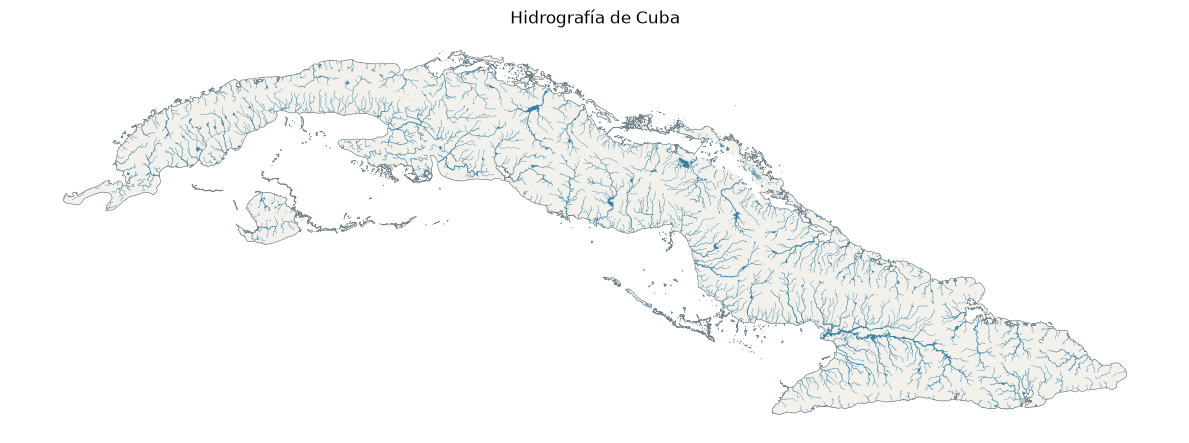

In [2]:
fig, ax = plt.subplots(figsize=(12, 9))

land.plot(ax=ax, color="#F2F1EB", edgecolor="none", zorder=1)
water_bodies.plot(ax=ax, color="#397FA3", edgecolor="none", zorder=2)

widths = {3: 0.20, 4: 0.30, 5: 0.45, 6: 0.65, 7: 0.90}
for order, width in widths.items():
    rivers.loc[rivers["ORD_STRAH"].eq(order)].plot(
        ax=ax, color="#397FA3", linewidth=width, zorder=3,
    )

coastline.plot(ax=ax, color="#74828A", linewidth=0.35, zorder=4)

ax.set_title("Hidrografía de Cuba")
ax.set_axis_off()
fig.tight_layout()
plt.show()

# to save the map, uncomment the following line
# fig.savefig(ROOT / "examples/hydrography_map.png", dpi=220, bbox_inches="tight")
